#  Gradient Boosting Regression – Regularization in Action

In this notebook, we’ll explore how **Gradient Boosting Regression** works in scikit-learn and how **regularization** helps prevent overfitting.

## What we do:
- Generate a simple 1D regression dataset for easy visualization
- Train **two Gradient Boosting models**:
  - One **without regularization**
  - One **with regularization** using:
    - `subsample`: row sampling to add randomness
    - `min_samples_split`: minimum number of samples to split a node

##  We compare:
- Fitted regression curves
- Mean Squared Error (MSE)
- R² Score (coefficient of determination)

##  Goal:
Understand how basic regularization settings can simplify the model and improve generalization in regression tasks.


Model without regularization:
MSE: 436.898087431509
R²: 0.9433474459257543

Model with regularization:
MSE: 416.22910374262773
R²: 0.9460275920508563


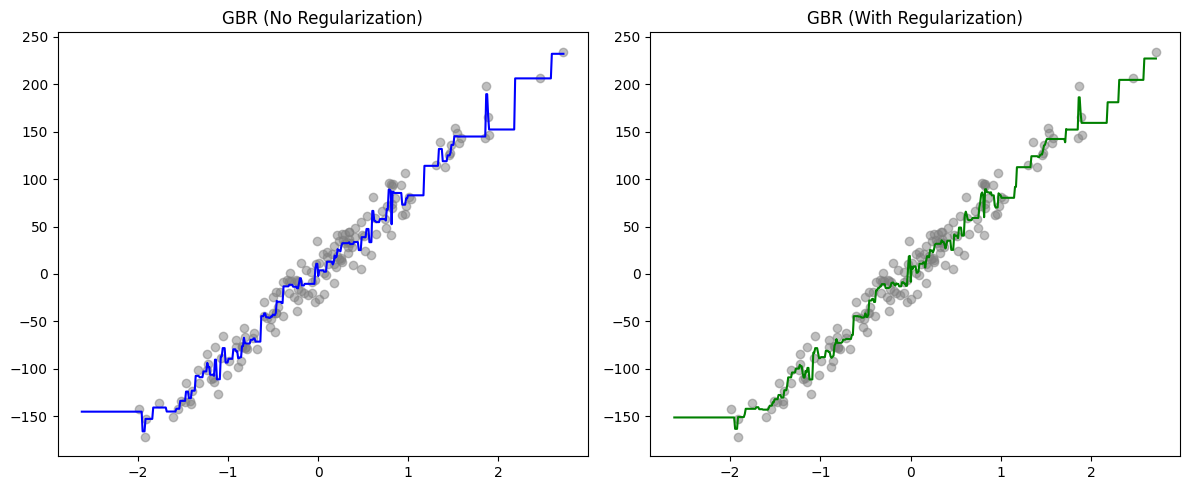

In [1]:
#  What we do:
# Train and compare two Gradient Boosting models (with and without regularization)

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Generate synthetic regression dataset
X, y = make_regression(n_samples=200, n_features=1, noise=15, random_state=42)

# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model 1: No regularization
gbr1 = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gbr1.fit(X_train, y_train)

# Model 2: With stronger regularization
#subsample=0.7

#    What it does: Uses only 70% of the training data randomly sampled for each tree.

#    Why: Adds randomness, reduces variance, helps generalization.

# min_samples_split=10

#    What it does: A node must have at least 10 samples to be split.

#    Why: Prevents the model from creating very small, overfitted branches


gbr2 = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3,
                                  subsample=0.7, min_samples_split=10, random_state=42)
gbr2.fit(X_train, y_train)

# Prediction and evaluation
y_pred1 = gbr1.predict(X_test)
y_pred2 = gbr2.predict(X_test)

print("Model without regularization:")
print("MSE:", mean_squared_error(y_test, y_pred1))
print("R²:", r2_score(y_test, y_pred1))

print("\nModel with regularization:")
print("MSE:", mean_squared_error(y_test, y_pred2))
print("R²:", r2_score(y_test, y_pred2))

# Plot prediction curves
X_plot = np.linspace(X.min(), X.max(), 500).reshape(-1, 1)
y_plot1 = gbr1.predict(X_plot)
y_plot2 = gbr2.predict(X_plot)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_train, y_train, color="gray", alpha=0.5)
plt.plot(X_plot, y_plot1, color="blue")
plt.title("GBR (No Regularization)")

plt.subplot(1, 2, 2)
plt.scatter(X_train, y_train, color="gray", alpha=0.5)
plt.plot(X_plot, y_plot2, color="green")
plt.title("GBR (With Regularization)")

plt.tight_layout()
plt.show()


## XGBoost Regularization Demo

In this example, we’ll visualize how **regularization parameters** (`lambda`, `gamma`) in **XGBoost** affect the decision boundaries of a classifier.

---

### What we do:

- Generate a simple 2D classification dataset using `make_moons`.
- Train two XGBoost models:
  - One **without regularization**
  - One **with strong regularization** (`lambda = 10`, `gamma = 5`)
- Visualize and compare their decision boundaries side-by-side.

---

###  Goal:

See how:
- `lambda` (**L2 penalty**)  
- and `gamma` (**minimum loss gain required to make a split**)  

help reduce **overfitting** by **smoothing** and **simplifying** the decision boundary.




/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:31:58] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:31:59] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy without regularization: 0.97
Accuracy with regularization: 0.90


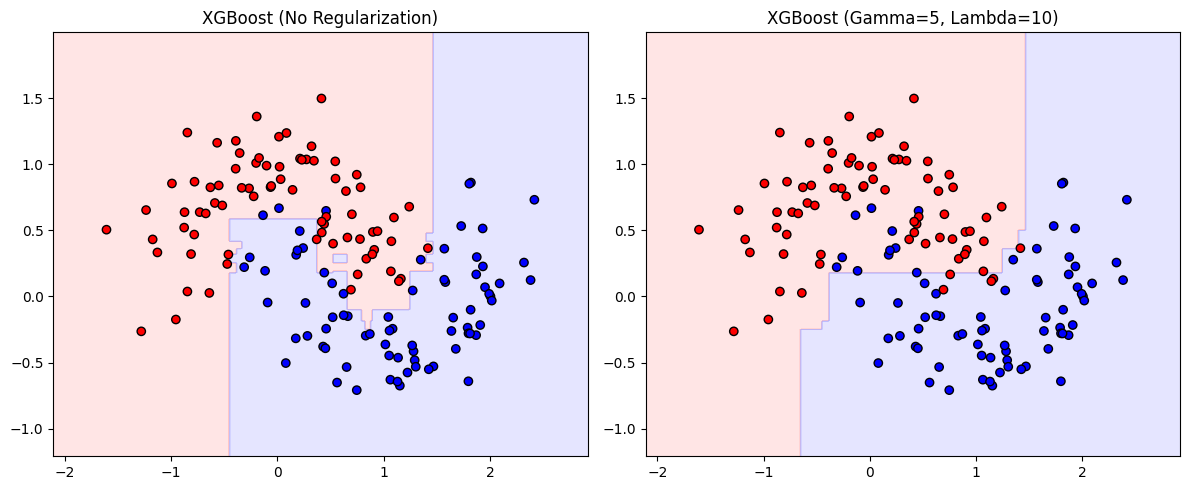

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
from matplotlib.colors import ListedColormap

# Generate a harder dataset
X, y = make_moons(n_samples=500, noise=0.25, random_state=42)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Define models
model_no_reg = XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                             gamma=0, reg_lambda=0, max_depth=3, n_estimators=30)
model_with_reg = XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                               gamma=10, reg_lambda=5, max_depth=3, n_estimators=30)

# Train models
model_no_reg.fit(X_train, y_train)
model_with_reg.fit(X_train, y_train)

# Accuracy
acc_no_reg = accuracy_score(y_test, model_no_reg.predict(X_test))
acc_with_reg = accuracy_score(y_test, model_with_reg.predict(X_test))
print(f"Accuracy without regularization: {acc_no_reg:.2f}")
print(f"Accuracy with regularization: {acc_with_reg:.2f}")

# Plotting function
def plot_decision_boundary(model, X, y, title, ax):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(['#FFAAAA', '#AAAAFF']))
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=ListedColormap(['red', 'blue']), edgecolor='k')
    ax.set_title(title)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_decision_boundary(model_no_reg, X_test, y_test, "XGBoost (No Regularization)", axes[0])
plot_decision_boundary(model_with_reg, X_test, y_test, "XGBoost (Gamma=5, Lambda=10)", axes[1])
plt.tight_layout()
plt.show()
